In [1]:
# !pip install langchain
# !pip install langchain-community
# !pip install -U langchain-google-genai
# !pip install --upgrade langchain-core langchain-google-vertexai
# !pip install --upgrade langchain-community duckduckgo-search
# !pip install langgraph
# !pip install requests pubchempy rdkit-pypi
# !pip install ctx-python
# !pip install biopython
# !pip install langgraph-checkpoint-sqlite
# !pip uninstall -y faiss-cpu
# !pip install langchain_openai python-dotenv
# !pip install "numpy<2"  # Use NumPy 1.x for compatibility with rdkit-pypi
# !pip install beautifulsoup4

In [1]:
import os
from typing import Optional

from dotenv import load_dotenv
from langchain_core.utils.utils import secret_from_env
from langchain_openai import ChatOpenAI
from pydantic import Field, SecretStr


load_dotenv()

class ChatOpenRouter(ChatOpenAI):
    openai_api_key: Optional[SecretStr] = Field(
        alias="api_key", default_factory=secret_from_env("OPENROUTER_API_KEY", default=None)
    )
    @property
    def lc_secrets(self) -> dict[str, str]:
        return {"openai_api_key": "OPENROUTER_API_KEY"}

    def __init__(self,
                 openai_api_key: Optional[str] = None,
                 **kwargs):
        openai_api_key = openai_api_key or os.environ.get("OPENROUTER_API_KEY")
        super().__init__(base_url="https://openrouter.ai/api/v1", openai_api_key=openai_api_key, **kwargs)


research_model = ChatOpenRouter(model_name="google/gemini-2.5-flash", temperature=0.0)

evaluator_model = ChatOpenRouter(model_name="openai/gpt-4o-mini", temperature=0.0)

/home/chen/proj/db_form_agent_system/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Import relevant functionality
from pathlib import Path
import re, logging, warnings, sqlite3, os, time, random, pickle, requests
import json
import copy
from typing import List, TypedDict

from langchain.chat_models import init_chat_model
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import create_react_agent
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage

# Enable verbose logging to see tool calls
logging.basicConfig(level=logging.WARNING, format='%(levelname)s | %(name)s | %(message)s')

# Disable noisy httpx logging
logging.getLogger('httpx').setLevel(logging.WARNING)

import sys
sys.path.append('../code')
from compound_tool import CompoundDatabaseTool
from searching_tool import FullTextJournalSearchTool
from fulltext_vector_tools import FullTextIndexTool, FullTextQueryTool

MAX_ITERATIONS = 20


def _vprint(*args, **kwargs):
    # set NODE_LOGS=1 to enable; anything else disables
    if os.getenv("NODE_LOGS", "1") in ("1", "true", "TRUE", "yes", "YES"):
        print(*args, **kwargs)

LITERATURE_AGENT_PROMPT = SystemMessage(
    content=Path("/home/chen/proj/db_form_agent_system/prompts/literature_agent.md").read_text()
)
CRITIQUE_AGENT_PROMPT = SystemMessage(
    content=Path("/home/chen/proj/db_form_agent_system/prompts/critique_agent.md").read_text()
)

tools = [
    CompoundDatabaseTool(),
    FullTextJournalSearchTool(results_base_dir="/home/chen/proj/db_form_agent_system/searching_results"),
    FullTextIndexTool(),
    FullTextQueryTool(),
]
# Create the agent with verbose=True
memory = MemorySaver()
agent_executor = create_react_agent(research_model, tools, prompt=LITERATURE_AGENT_PROMPT, checkpointer=memory)
critique_agent_executor = create_react_agent(evaluator_model, tools, prompt=CRITIQUE_AGENT_PROMPT, checkpointer=memory)


class StateHistory(TypedDict):
    claim: str
    confidence_score: float
    supporting_sources: List[str]
    tool_name: str | None
    stop_reason: str | None


class AgentState(TypedDict):
    messages: List[HumanMessage | AIMessage]
    original_query: str
    stop_history: List[StateHistory]
    consecutive_no_new_evidence: int
    consecutive_stagnant_claim: int
    consecutive_tool_unavailable: int
    last_critique_signature: str | None
    consecutive_clarify_without_progress: int

   
def researcher_node(state: AgentState):
    _vprint("-----Researcher Node Invoked-----")
    last = state["messages"][-1].content if state.get("messages") else ""
    next_query = None
    m = re.search(r"\{[\s\S]*\}", str(last))
    if m:
        try:
            obj = json.loads(m.group(0))
            if (obj.get("decision","") or "").lower() == "clarify":
                next_query = obj.get("next_query")
        except json.JSONDecodeError:
            pass
    if not next_query and "clarify" in str(last).lower():
        try:
            obj = json.loads(m.group(0)) if m else {}
            next_query = obj.get("next_query") or None
        except Exception:
            pass

    if next_query:
        merged = (
            f"Original question:\n{state.get('original_query','')}\n\n"
            f"Follow-up request from reviewer:\n{next_query}\n\n"
            "Answer the follow-up strictly in the context of the original question."
        )
        input_messages = [HumanMessage(content=merged)]
    else:
        input_messages = state["messages"]

    result = agent_executor.invoke({"messages": input_messages})
    return {"messages": state["messages"] + [AIMessage(content=result['messages'][-1].content)]}



def critique_node(state: AgentState):
    _vprint("-----Critique Node Invoked-----")
    last_message = state["messages"][-1].content
    original = state.get("original_query", "")
    critique_input = f"Original question: {original}\nResearcher output:\n{last_message}"
    critique_result = critique_agent_executor.invoke({"messages": [HumanMessage(content=critique_input)]})
    critique_content = critique_result['messages'][-1].content
    raw = (critique_content or "").strip()

    parsed: dict | None = None
    try:
        candidate = json.loads(raw)
        if isinstance(candidate, dict):
            parsed = candidate
    except Exception:
        pass
    if parsed is None:
        match = re.search(r"\{[\s\S]*?\}", raw)
        if match:
            try:
                candidate = json.loads(match.group(0))
                if isinstance(candidate, dict):
                    parsed = candidate
            except Exception:
                parsed = None

    stop_reason = None
    supporting_sources: List[str] = []
    tool_name: str | None = None

    if parsed:
        candidate_reason = parsed.get("stop_reason")
        if isinstance(candidate_reason, str) and candidate_reason.strip():
            stop_reason = candidate_reason.strip().upper()
        sources = parsed.get("supporting_sources")
        if isinstance(sources, list):
            supporting_sources = [str(item) for item in sources]
        candidate_tool = parsed.get("tool_name")
        if isinstance(candidate_tool, str) and candidate_tool.strip():
            tool_name = candidate_tool.strip()

    def _last_researcher_json(messages):
        if not messages:
            return ""
        for msg in reversed(messages):
            content = getattr(msg, "content", "") or ""
            if '"synthesis"' in content:
                return content
        return ""

    def _safe_float(value):
        try:
            if isinstance(value, (int, float)):
                return float(value)
            if isinstance(value, str):
                return float(value.replace("–", "-").strip())
        except Exception:
            return None
        return None

    def _extract_claim_and_confidence(messages):
        blob = _last_researcher_json(messages)
        claim = "Unclear"
        confidence = 0.0
        if not blob:
            return claim, confidence
        try:
            obj = json.loads(blob)
            synthesis = obj.get("synthesis", {}) if isinstance(obj, dict) else {}
            claim = (synthesis.get("claim") or "").strip().capitalize() if isinstance(synthesis, dict) else ""
            candidate_conf = _safe_float(synthesis.get("confidence_score")) if isinstance(synthesis, dict) else None
            if candidate_conf is not None:
                confidence = max(0.0, min(1.0, candidate_conf))
        except Exception:
            pass
        if claim == "Unclear":
            match_claim = re.search(r'"claim"\s*:\s*"([^"]+)"', blob)
            if match_claim:
                claim = match_claim.group(1).strip().capitalize()
        if confidence == 0.0:
            match_conf = re.search(r'"confidence_score"\s*:\s*("?)([0-9]*\.?[0-9]+)\1', blob)
            if match_conf:
                candidate = _safe_float(match_conf.group(2))
                if candidate is not None:
                    confidence = max(0.0, min(1.0, candidate))
        return claim, confidence

    claim, confidence = _extract_claim_and_confidence(state.get("messages", []))

    history = copy.deepcopy(state.get("stop_history", []))
    history.append({
        "claim": claim,
        "confidence_score": confidence,
        "supporting_sources": supporting_sources,
        "tool_name": tool_name,
        "stop_reason": stop_reason,
    })

    prev_no_new = state.get("consecutive_no_new_evidence", 0)
    prev_stagnant = state.get("consecutive_stagnant_claim", 0)
    prev_tool_unavailable = state.get("consecutive_tool_unavailable", 0)
    clarify_without_progress = state.get("consecutive_clarify_without_progress", 0)
    previous_signature = state.get("last_critique_signature") or ""

    raw_signature = json.dumps(parsed, sort_keys=True) if parsed else raw

    no_new = prev_no_new
    stagnant = prev_stagnant
    tool_unavailable = prev_tool_unavailable

    decision = parsed.get("decision") if parsed else None
    if isinstance(decision, str) and decision.lower() == "clarify" and not stop_reason:
        if raw_signature == previous_signature:
            clarify_without_progress += 1
        else:
            clarify_without_progress = 1
        if clarify_without_progress >= 3:
            stop_reason = "STAGNANT_CLAIM"
            stagnant = max(stagnant, clarify_without_progress)
    else:
        clarify_without_progress = 0

    if not stop_reason and (isinstance(decision, str) and decision.lower() == "clarify") and clarify_without_progress >= 2:
        stop_reason = "NO_NEW_EVIDENCE"
        history[-1]["stop_reason"] = stop_reason
        no_new = prev_no_new + 1

    if history:
        history[-1]["stop_reason"] = stop_reason

    _vprint(f"[critique_node] stop_reason={stop_reason}, clarify_without_progress={clarify_without_progress}")

    patched_content = critique_content
    if parsed is not None:
        patched = dict(parsed)
        if stop_reason:
            patched["stop_reason"] = stop_reason
        patched_content = json.dumps(patched, indent=2)

    _vprint(f"[critique_node] stop_reason={stop_reason}, clarify_without_progress={clarify_without_progress}")

    return {
        "messages": state["messages"] + [AIMessage(content=patched_content)],
        "stop_history": history,
        "consecutive_no_new_evidence": no_new,
        "consecutive_stagnant_claim": stagnant,
        "consecutive_tool_unavailable": tool_unavailable,
        "last_critique_signature": raw_signature,
        "consecutive_clarify_without_progress": clarify_without_progress,
    }

    
def should_continue(state: AgentState):
    """Decide whether to continue the loop using critique stop reasons.

    Primary stop signals (immediate):
      - stop_reason in {APPROVED, NO_NEW_EVIDENCE, STAGNANT_CLAIM, TOOL_UNAVAILABLE, FUTILITY_DETECTED}

    Legacy fallbacks are preserved for safety if stop_reason is unavailable.
    """
    last_message_content = state["messages"][-1].content if state.get("messages") else ""
    raw = (last_message_content or "").strip()
    _vprint(f"[should_continue] raw critique output: {raw}...")

    STOP_REASONS = {"APPROVED", "NO_NEW_EVIDENCE", "STAGNANT_CLAIM", "TOOL_UNAVAILABLE", "FUTILITY_DETECTED"}

    def _normalized_reason(value) -> str | None:
        if isinstance(value, str) and value.strip():
            return value.strip().upper()
        return None

    history = state.get("stop_history") or []
    if history:
        latest_reason = _normalized_reason(history[-1].get("stop_reason"))
        if latest_reason in STOP_REASONS:
            _vprint(f"-----Agent Decided to Stop (history stop_reason={latest_reason})-----")
            return END

    if state.get("consecutive_clarify_without_progress", 0) >= 5:
        _vprint("-----Agent Decided to Stop (clarify stagnation >=5)-----")
        return END

    def _should_stop_from_json(obj: dict) -> bool:
        stop_reason = _normalized_reason(obj.get("stop_reason"))
        if stop_reason in STOP_REASONS:
            _vprint(f"-----Agent Decided to Stop (stop_reason={stop_reason})-----")
            return True

        decision = obj.get("decision")
        if isinstance(decision, str) and decision.lower() == "approve":
            _vprint("-----Agent Decided to Stop (legacy decision=approve)-----")
            return True

        try:
            score = float(obj.get("agreement_score", 0.0))
            if score > 0.75:
                _vprint(f"-----Agent Decided to Stop (legacy agreement_score={score:.2f} > 0.75)-----")
                return True
        except Exception:
            pass

        return False

    try:
        critique_json = json.loads(raw)
        if isinstance(critique_json, dict) and _should_stop_from_json(critique_json):
            return END
    except Exception:
        pass

    match = re.search(r"\{[\s\S]*?\}", raw)
    if match:
        try:
            critique_json = json.loads(match.group(0))
            if isinstance(critique_json, dict) and _should_stop_from_json(critique_json):
                _vprint("-----Agent Decided to Stop (extracted JSON)-----")
                return END
        except Exception:
            pass

    low = raw.lower()
    if any(token in low for token in ["approve", "approved"]):
        _vprint("-----Agent Decided to Stop (text match)-----")
        return END

    return "researcher"
# Build the graph
workflow = StateGraph(AgentState)
workflow.add_node("researcher", researcher_node)
workflow.add_node("critique", critique_node)
workflow.set_entry_point("researcher")
workflow.add_edge("researcher", "critique")
workflow.add_conditional_edges("critique", should_continue)

app = workflow.compile(checkpointer=memory)

In [3]:
import os
import re
import json
import time
from datetime import datetime
from langchain_core.messages import HumanMessage, AIMessage

# -------------------- helpers --------------------

def _last_researcher_json(messages):
    """Return the last message content that contains a 'synthesis' JSON, else ''."""
    if not messages:
        return ""
    for msg in reversed(messages):
        content = getattr(msg, "content", "") or ""
        if '"synthesis"' in content:
            return content
    return ""


def determine_final_claim(messages):
    """Read 'synthesis.claim' with minimal normalization."""
    blob = _last_researcher_json(messages)
    if not blob:
        return "Unclear"
    try:
        obj = json.loads(blob)
        syn = obj.get("synthesis", {}) if isinstance(obj, dict) else {}
        claim_raw = syn.get("claim")
        if isinstance(claim_raw, str) and claim_raw.strip():
            return claim_raw.strip()
    except Exception:
        pass

    m = re.search(r'"claim"\s*:\s*"([^"]+)"', blob)
    if m:
        candidate = m.group(1).strip()
        if candidate:
            return candidate
    return "Unclear"


def _safe_float(x):
    try:
        if isinstance(x, (int, float)):
            return float(x)
        if isinstance(x, str):
            return float(x.replace("–", "-").strip())
    except Exception:
        return None


def determine_confidence_score(messages):
    """
    Reads numeric 'synthesis.confidence_score' (0..1).
    If missing/unparseable, returns 0.0 (so it won't cross 0.45).
    """
    blob = _last_researcher_json(messages)
    if not blob:
        return 0.0
    try:
        obj = json.loads(blob)
        syn = obj.get("synthesis", {}) if isinstance(obj, dict) else {}
        score = syn.get("confidence_score")
        return _safe_float(score)
    except Exception:
        pass
    m = re.search(r'"confidence_score"\s*:\s*([0-9.]+)', blob)
    if m:
        try:
            return float(m.group(1))
        except Exception:
            pass
    return 0.0


In [4]:


def main():
    _vprint("\n🧪 Analytical Chemistry Agent Ready!")
    while True:
        query = input("\n📝 Enter your question (or 'quit' to exit): ")
        _vprint(f"\n>>> User input query: {query}\n", flush=True)
        if query.lower() == 'quit':
            break

        query_timestamp = datetime.utcnow().strftime("%Y%m%d_%H%M%S")
        query_results_dir = f"/home/chen/proj/db_form_agent_system/searching_results/run_{query_timestamp}"
        os.environ["SEARCH_SESSION_DIR"] = query_results_dir
        _vprint(f"📁 All results will be saved to: searching_results/run_{query_timestamp}\n")

        requested_labels: list[str] = []
        directive = query
        match = re.search(r"(?i)answer:\s*(.*)", query)
        if match:
            raw_segment = match.group(1)
            candidates = [label.strip() for label in re.findall(r'"([^\"]+)"', raw_segment)]
            for label in candidates:
                if label and label not in requested_labels:
                    requested_labels.append(label)
            if requested_labels:
                label_text = ", ".join(f'"{label}"' for label in requested_labels)
                directive = (
                    f"{query}\n\nInstruction: ensure synthesis.claim exactly matches one of the user-specified answer options: {label_text}. "
                    "Select the option best supported by the evidence."
                )

        init_message = HumanMessage(content=directive)
        init_state = {
            'messages': [init_message],
            'original_query': query,
            'stop_history': [],
            'consecutive_no_new_evidence': 0,
            'consecutive_stagnant_claim': 0,
            'consecutive_tool_unavailable': 0,
            'last_critique_signature': None,
            'consecutive_clarify_without_progress': 0,
        }

        thread_id = f"qa_session_{int(time.time())}"
        last_event_state = None
        for event in app.stream(init_state, config={'configurable': {'thread_id': thread_id}, 'recursion_limit': 20}):
            for v in event.values():
                last_event_state = v
                try:
                    content = v['messages'][-1].content
                    try:
                        import json
                        obj = json.loads(content)
                        _vprint(json.dumps(obj, indent=2))
                    except json.JSONDecodeError:
                        _vprint(content)
                except Exception:
                    _vprint(str(v))

        claim = 'Unclear'
        score = 0.0
        critique_decision = None
        critique_json = {}
        if last_event_state and last_event_state.get('messages'):
            claim = determine_final_claim(last_event_state['messages'])
            score = determine_confidence_score(last_event_state['messages']) or 0.0

        display_label = claim.strip() if isinstance(claim, str) and claim.strip() else "Unclear"
        if last_event_state and last_event_state.get('messages'):
            critique_msg = last_event_state['messages'][-1]
            critique_raw = getattr(critique_msg, 'content', '') or ''
            try:
                critique_json = json.loads(critique_raw)
            except Exception:
                match_json = re.search(r"\{[\s\S]*?\}", critique_raw)
                if match_json:
                    try:
                        critique_json = json.loads(match_json.group(0))
                    except Exception:
                        critique_json = {}
            if isinstance(critique_json, dict):
                decision_val = critique_json.get('decision')
                if isinstance(decision_val, str):
                    critique_decision = decision_val.strip().lower()

        _vprint(f"\n=== FINAL DECISION: {display_label} (confidence {score:.2f}) ===")
        if critique_decision:
            _vprint(f"    critique decision: {critique_decision}")
        _vprint(f"    researcher claim: {claim}")


if __name__ == '__main__':
    main()



🧪 Analytical Chemistry Agent Ready!

>>> User input query: is biotin endogenous metabolite from human? Answer: "Endogenous" or "Exogenous"

📁 All results will be saved to: searching_results/run_20251015_003057

-----Researcher Node Invoked-----
{
  "synthesis": {
    "claim": "Exogenous",
    "explanation": "While biotin is essential for human health, the available literature suggests that humans cannot synthesize biotin endogenously. It is considered a vitamin, meaning it must be obtained from external sources (diet). The search results indicate that biotin is a dietary requirement and its metabolism is studied in humans, but not its biosynthesis within the human body.",
    "confidence_score": 0.7,
    "limitations": "The full-text indexing failed, so the evidence is based on titles and abstracts. A more thorough search of full texts might reveal nuanced information about potential trace endogenous production or specific conditions, but current understanding points to exogenous acqu

In [ ]:
# is TG(i-16:0/a-17:0/18:0)[rac] endogenous metabolite from human? Answer: "Endogenous" or "Exogenous"

In [5]:
import pandas as pd
from tqdm import tqdm


def is_endogenous_compound(compound_name: str) -> str:
    prompt = f"Is the compound '{compound_name}' an endogenous metabolite from human? Answer 'Endogenous', 'Exogenous'."

    query_timestamp = datetime.utcnow().strftime("%Y%m%d_%H%M%S")
    query_results_dir = f"/home/chen/proj/db_form_agent_system/searching_results/run_{query_timestamp}"
    os.environ["SEARCH_SESSION_DIR"] = query_results_dir

    requested_labels: list[str] = []
    match = re.search(r"(?i)answer:\s*(.*)", prompt)
    if match:
        raw_segment = match.group(1)
        candidates = [label.strip() for label in re.findall(r'"([^\"]+)"', raw_segment)]
        for label in candidates:
            if label and label not in requested_labels:
                requested_labels.append(label)
        if requested_labels:
            label_text = ", ".join(f'"{label}"' for label in requested_labels)
            prompt = (
                f"{prompt}\n\nInstruction: ensure synthesis.claim exactly matches one of the user-specified answer options: {label_text}. "
                "Select the option best supported by the evidence."
            )

    init_message = HumanMessage(content=prompt)
    init_state = {
        'messages': [init_message],
        'original_query': prompt,
        'stop_history': [],
        'consecutive_no_new_evidence': 0,
        'consecutive_stagnant_claim': 0,
        'consecutive_tool_unavailable': 0,
        'last_critique_signature': None,
        'consecutive_clarify_without_progress': 0,
    }

    thread_id = f"qa_session_{int(time.time())}"
    last_event_state = None
    for event in app.stream(init_state, config={'configurable': {'thread_id': thread_id}, 'recursion_limit': 20}):
        for v in event.values():
            last_event_state = v
            try:
                _vprint(v['messages'][-1].content)
            except Exception:
                _vprint(str(v))

    claim = 'Unclear'

    if last_event_state and last_event_state.get('messages'):
        claim = determine_final_claim(last_event_state['messages'])

    return claim


df = pd.read_csv("/data/chen/data/hmdb/metabolites.csv")

# get 100 rows with 80% endogenous
df_endogenous = df[df['Endogenous']=='Yes'].sample(n=45, random_state=42)
df_non_endogenous = df[df['Endogenous']=='No'].sample(n=5, random_state=42)
df_sampled = pd.concat([df_endogenous, df_non_endogenous]).reset_index(drop=True)

tqdm.pandas(desc="Checking compounds") 
df_sampled['Endogenous_LLM'] = df_sampled['Name'].progress_apply(is_endogenous_compound)
df_sampled[['Name', 'Endogenous', 'Endogenous_LLM']]


Checking compounds:   0%|          | 0/50 [00:00<?, ?it/s]

-----Researcher Node Invoked-----


/home/chen/proj/db_form_agent_system/notebooks/../code/fulltext_vector_tools.py:48: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-huggingface package and should be used instead. To use it run `pip install -U :class:`~langchain-huggingface` and import as `from :class:`~langchain_huggingface import HuggingFaceEmbeddings``.
  return SentenceTransformerEmbeddings(model_name="all-MiniLM-L6-v2")


THOUGHT: The previous query for "iso-16:0 human endogenous synthesis" did not yield direct evidence of endogenous synthesis for this specific fatty acid. The results were more general about fatty acid metabolism or extraction methods.

The current evidence suggests that branched-chain fatty acids (BCFAs) are present in humans and can be incorporated into triglycerides. However, the *endogenous* synthesis of specific BCFAs like iso-16:0 and anteiso-17:0 by human cells, as opposed to dietary intake or microbial production, remains unclear.

Given the lack of direct evidence for *de novo* human synthesis of these specific BCFAs, and the known dietary and microbial sources of BCFAs, it is difficult to definitively classify the entire triglyceride as "Endogenous". However, the presence of these fatty acids in human systems and their incorporation into triglycerides makes it "Plausible" that such a triglyceride could be found in humans, even if its ultimate origin is not purely endogenous sy

WARNING | fulltext_journal_search | Entrez error (attempt 1/3): HTTP Error 429: Too Many Requests


THOUGHTS:
The search results provide some crucial information.

From "Branched-Long-Chain Monomethyl Fatty Acids: Are They Hidden Gems?" (PMID: 37982580):
*   "BLCFA can be obtained from many common foods, such as ruminant products (milk, cheese, and meat), fish, chia seeds, fermented foods, and others." This suggests an exogenous source.
*   "Also, BLCFA are normal constituents of human tissues/cells because they exist in vernix caseosa, sebaceous gland, skin, and blood." This indicates their presence in humans.
*   "The incorporation of iso-16:0, anteiso-17:0, and iso-18:0 into H4 cell lipids was in the order of PL > TAG > CE > DAG > FFA > MAG." This explicitly mentions the incorporation of iso-16:0 and anteiso-17:0 into TAG (triglycerides) in H4 cells (a human cell line).
*   The paper also mentions that BLCFA can be "extended by ELOVL1, ELOVL3, ELOVL6, and ELOVL7" and "FADS2 mediates the Δ6-desaturation of BLCFA." This hints at some metabolic processing, but not necessarily *de nov

... (115 outputs left out)

[critique_node] stop_reason=APPROVED, clarify_without_progress=0
[critique_node] stop_reason=APPROVED, clarify_without_progress=0
[should_continue] raw critique output: {
  "decision": "approve",
  "reasoning": "Answer: Exogenous. The evidence clearly supports that potassium is an essential nutrient obtained from dietary sources, not synthesized by the body, aligning...
-----Agent Decided to Stop (history stop_reason=APPROVED)-----
{
  "decision": "approve",
  "reasoning": "Answer: Exogenous. The evidence clearly supports that potassium is an essential nutrient obtained from dietary sources, not synthesized by the body, aligning with the claim made.",
  "next_query": "",
  "quality_checks": {
    "json_shape_ok": true,
    "claim_justified": true,
    "human_specific": true,
    "identification_confidence_ok": true,
    "evidence_diverse_sources": true
  },
  "stop_reason": "APPROVED"
}
-----Researcher Node Invoked-----
{"synthesis": {"claim": "Unclear", "explanation": "The search resu

Checking compounds: 100%|██████████| 50/50 [2:22:52<00:00, 171.46s/it]

[critique_node] stop_reason=APPROVED, clarify_without_progress=0
[critique_node] stop_reason=APPROVED, clarify_without_progress=0
[should_continue] raw critique output: {
  "decision": "approve",
  "reasoning": "Answer: Exogenous. The evidence consistently identifies erythrosine as a food additive and an external agent affecting human physiology, with no indication o...
-----Agent Decided to Stop (history stop_reason=APPROVED)-----
{
  "decision": "approve",
  "reasoning": "Answer: Exogenous. The evidence consistently identifies erythrosine as a food additive and an external agent affecting human physiology, with no indication of endogenous production.",
  "next_query": "",
  "quality_checks": {
    "json_shape_ok": true,
    "claim_justified": true,
    "human_specific": true,
    "identification_confidence_ok": true,
    "evidence_diverse_sources": true
  },
  "stop_reason": "APPROVED"
}


,Name,Endogenous,Endogenous_LLM
0,TG(i-16:0/a-17:0/18:0)[rac],Yes,Exogenous
1,TG(i-22:0/i-18:0/a-25:0)[rac],Yes,Unclear
2,Alanylarginine,Yes,Unclear
3,"CL(18:1(9Z)/16:0/22:5(4Z,7Z,10Z,13Z,16Z)/18:1(...",Yes,Endogenous
4,TG(12:0/i-20:0/14:0),Yes,Unclear
5,TG(i-17:0/i-16:0/i-15:0),Yes,Unclear
6,TG(18:0/a-21:0/i-19:0)[rac],Yes,Exogenous
7,"CL(i-12:0/14:0/18:2(9Z,11Z)/18:2(9Z,11Z))",Yes,Unclear
8,S-4'-Hydroxywarfarin,Yes,Exogenous
9,"PC(18:0/22:5(4Z,7Z,10Z,13Z,16Z))",Yes,Unclear


In [9]:
df_sampled[['Name', 'Endogenous', 'Endogenous_LLM']]

,Name,Endogenous,Endogenous_LLM
0,TG(i-16:0/a-17:0/18:0)[rac],Yes,Exogenous
1,TG(i-22:0/i-18:0/a-25:0)[rac],Yes,Unclear
2,Alanylarginine,Yes,Unclear
3,"CL(18:1(9Z)/16:0/22:5(4Z,7Z,10Z,13Z,16Z)/18:1(...",Yes,Endogenous
4,TG(12:0/i-20:0/14:0),Yes,Unclear
5,TG(i-17:0/i-16:0/i-15:0),Yes,Unclear
6,TG(18:0/a-21:0/i-19:0)[rac],Yes,Exogenous
7,"CL(i-12:0/14:0/18:2(9Z,11Z)/18:2(9Z,11Z))",Yes,Unclear
8,S-4'-Hydroxywarfarin,Yes,Exogenous
9,"PC(18:0/22:5(4Z,7Z,10Z,13Z,16Z))",Yes,Unclear


Text(0.5, 14.722222222222216, 'Predicted Label')

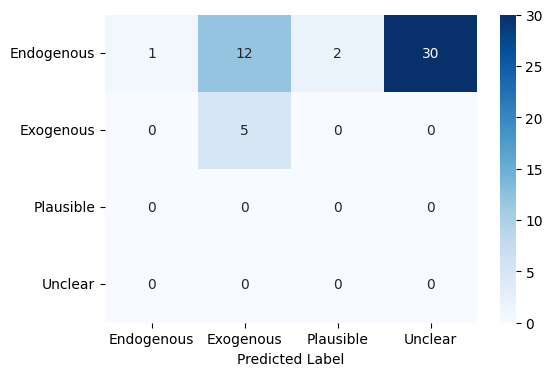

In [15]:
# plot the confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(df_sampled['Endogenous'].map({'No': "Exogenous", 'Yes': "Endogenous"}), df_sampled['Endogenous_LLM'])
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Endogenous', 'Exogenous', 'Plausible', 'Unclear'], yticklabels=['Endogenous', 'Exogenous', 'Plausible', 'Unclear'])
plt.xlabel('Predicted Label')

In [ ]:
df_sampled

In [ ]:
import pandas as pd
df = pd.read_csv('/data/chen/data/hmdb/metabolites_endo_exo.csv')

df['Endogenous_LLM'] = df['Name'].apply(is_endogenous_compound)
df[['Name', 'Origin', 'Endogenous_LLM']]